# Urban Mobility and Economic Performance Analysis

**Author:** Roberto Blanco Lugo   
**Tools:** Python, Pandas, Matplotlib  
**Project type:** Exploratory Data Analysis  

## Introduction

This project analyzes urban mobility and economic indicators in Latin American cities to identify patterns that may support decision-making in urban planning and public policy.

The analysis focuses on preparing, cleaning, merging and exploring mobility and economic datasets to compare congestion-related indicators with economic variables across selected cities.

## 1. Data Loading and Initial Exploration


In [4]:
# Import required libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [5]:
# Load datasets
traffic = pd.read_csv('../data/tomtom_traffic.csv')
eco = pd.read_csv('../data/oecd_city_economy.csv')

In [6]:
# Preview the traffic dataset
traffic.head()

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [7]:
# Preview the economic dataset
eco.head()

,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"



# 2. Data Preparation
## 2.1 Dataset Inspection

In [8]:
# Inspect the traffic dataset
traffic.info()
traffic.head(3)
traffic.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  str    
 1   City                            1004464 non-null  str    
 2   UpdateTimeUTC                   1004464 non-null  str    
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  str    
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  float64
dtypes: float64(

Country                           0
City                              0
UpdateTimeUTC                     0
JamsDelay                         0
TrafficIndexLive                  0
JamsLengthInKms                   0
JamsCount                         0
TrafficIndexWeekAgo               0
UpdateTimeUTCWeekAgo              0
TravelTimeLivePer10KmsMins        0
TravelTimeHistoricPer10KmsMins    0
MinsDelay                         0
dtype: int64

### Data Inspection

The `traffic` dataset shows the following characteristics:

- The `update_time_utc` and `update_time_utc_week_ago` columns were successfully converted to the `datetime` data type.
- The remaining traffic metrics are stored as numeric values (`float64`), making them suitable for statistical analysis and visualization.
- The categorical variables (`country` and `city`) are stored as text (`object`), which is appropriate for grouping and merging operations.
- No missing values were detected after the data cleaning process, indicating that the dataset is complete and ready for further analysis.

In [9]:
# Inspect the economic dataset
eco.info()
eco.head(3)
eco.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Year             30 non-null     int64
 1   City             30 non-null     str  
 2   Country          30 non-null     str  
 3   City GDP/capita  30 non-null     str  
 4   Unemployment %   30 non-null     str  
 5   PM2.5 (μg/m³)    30 non-null     str  
 6   Population (M)   30 non-null     str  
dtypes: int64(1), str(6)
memory usage: 1.8 KB


Year               0
City               0
Country            0
City GDP/capita    0
Unemployment %     0
PM2.5 (μg/m³)      0
Population (M)     0
dtype: int64

In [10]:
# Inspect the economic dataset
eco.info()
eco.head(3)
eco.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Year             30 non-null     int64
 1   City             30 non-null     str  
 2   Country          30 non-null     str  
 3   City GDP/capita  30 non-null     str  
 4   Unemployment %   30 non-null     str  
 5   PM2.5 (μg/m³)    30 non-null     str  
 6   Population (M)   30 non-null     str  
dtypes: int64(1), str(6)
memory usage: 1.8 KB


Year               0
City               0
Country            0
City GDP/capita    0
Unemployment %     0
PM2.5 (μg/m³)      0
Population (M)     0
dtype: int64

### Data Inspection

The `eco` dataset has the following characteristics:

- The numeric variables (`city_gdp_capita`, `unemployment_pct`, and `population_m`) were successfully converted to numeric data types.
- A new variable, `population`, was created by converting the population values from millions to absolute numbers.
- The dataset contains the required economic indicators for each city and year, making it suitable for integration with the traffic dataset.
- The data preparation process ensures consistency and compatibility for the subsequent merge operation.

### 2.2 Rename Columns


In [11]:
# Rename columns in the traffic dataset
traffic = traffic.rename(columns={
    'Country': 'country',
    'City': 'city',
    'UpdateTimeUTC': 'update_time_utc',
    'JamsDelay': 'jams_delay',
    'TrafficIndexLive': 'traffic_index_live',
    'JamsLengthInKms': 'jams_length_in_kms',
    'JamsCount': 'jams_count',
    'TrafficIndexWeekAgo': 'traffic_index_week_ago',
    'UpdateTimeUTCWeekAgo': 'update_time_utc_week_ago',
    'TravelTimeLivePer10KmsMins': 'travel_time_live_per_10kms_mins',
    'TravelTimeHistoricPer10KmsMins': 'travel_time_historic_per_10kms_mins',
    'MinsDelay': 'mins_delay'
})
# Verify the updated column names
traffic.columns

Index(['country', 'city', 'update_time_utc', 'jams_delay',
       'traffic_index_live', 'jams_length_in_kms', 'jams_count',
       'traffic_index_week_ago', 'update_time_utc_week_ago',
       'travel_time_live_per_10kms_mins',
       'travel_time_historic_per_10kms_mins', 'mins_delay'],
      dtype='str')

In [12]:
# Rename columns in the economic dataset
eco = eco.rename(columns={
    'Year': 'year',
    'City': 'city',
    'Country': 'country',
    'City GDP/capita': 'city_gdp_capita',
    'Unemployment %': 'unemployment_pct',
    'PM2.5 (μg/m³)': 'pm25',
    'Population (M)': 'population_m'
})
# Verify the updated column names
eco.columns

Index(['year', 'city', 'country', 'city_gdp_capita', 'unemployment_pct',
       'pm25', 'population_m'],
      dtype='str')


### 2.3 Correct Numeric and Date Formats


In [13]:
# Convert date columns in the traffic dataset
traffic['update_time_utc'] = pd.to_datetime(
    traffic['update_time_utc'],
    errors='coerce'
)
traffic['update_time_utc_week_ago'] = pd.to_datetime(
    traffic['update_time_utc_week_ago'],
    errors='coerce'
)

# Verify the data types
traffic.info()

<class 'pandas.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                               Non-Null Count    Dtype         
---  ------                               --------------    -----         
 0   country                              1004464 non-null  str           
 1   city                                 1004464 non-null  str           
 2   update_time_utc                      1004464 non-null  datetime64[us]
 3   jams_delay                           1004464 non-null  float64       
 4   traffic_index_live                   1004464 non-null  float64       
 5   jams_length_in_kms                   1004464 non-null  float64       
 6   jams_count                           1004464 non-null  float64       
 7   traffic_index_week_ago               1004464 non-null  float64       
 8   update_time_utc_week_ago             1004464 non-null  datetime64[us]
 9   travel_time_live_per_10kms_mins      1004464 non-null  float64      

In [14]:

# Clean numeric columns
eco['city_gdp_capita'] = (
    eco['city_gdp_capita']
    .astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)
eco['unemployment_pct'] = (
    eco['unemployment_pct']
    .astype(str)
    .str.replace('%', '', regex=False)
    .str.replace(',', '.', regex=False)
    .astype(float)
)
eco['population_m'] = (
    eco['population_m']
    .astype(str)
    .str.replace(',', '.', regex=False)
    .astype(float)
)

# Calculate total population
eco['population'] = eco['population_m'] * 1000000

# Verify the data types
eco.info()
eco.head(3)


<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   year              30 non-null     int64  
 1   city              30 non-null     str    
 2   country           30 non-null     str    
 3   city_gdp_capita   30 non-null     float64
 4   unemployment_pct  30 non-null     float64
 5   pm25              30 non-null     str    
 6   population_m      30 non-null     float64
 7   population        30 non-null     float64
dtypes: float64(4), int64(1), str(3)
memory usage: 2.0 KB


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
0,2023,buenos-aires,Argentina,15782.0,6.2,"15,2",15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,"29,50",22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,"19,10",13.6,13600000.0



## 3. Data Integration
### 3.1 Merge Datasets

In [15]:
# Extract year from dates
traffic['year'] = traffic['update_time_utc'].dt.year

# Verify changes
traffic.head(3)

,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,mins_delay,year
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437,2025
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635,2025
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232,2025


In [16]:
# Filter records for 2024
traffic_2024 = traffic[traffic['year'] == 2024].copy()
eco_2024 = eco[eco['year'] == 2024].copy()

# Preview filtered datasets
display(traffic_2024.head())
display(eco_2024.head())


,country,city,update_time_utc,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,traffic_index_week_ago,update_time_utc_week_ago,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,mins_delay,year
302,ARE,abu-dhabi,2024-12-31 23:01:30.000,12.9,5.0,2.5,5.0,2.0,2024-12-24 23:01:30.001,8.560399,8.519634,0.040765,2024
303,ARE,abu-dhabi,2024-12-31 22:01:30.000,136.0,21.0,20.6,32.0,3.0,2024-12-24 22:01:30.000,10.355732,9.049445,1.306286,2024
304,ARE,abu-dhabi,2024-12-31 21:16:30.000,455.2,31.0,40.4,72.0,4.0,2024-12-24 21:01:30.000,11.456878,9.305174,2.151704,2024
305,ARE,abu-dhabi,2024-12-31 20:01:00.001,399.4,27.0,38.0,75.0,6.0,2024-12-24 20:01:30.001,11.670062,9.952811,1.717252,2024
306,ARE,abu-dhabi,2024-12-31 19:46:00.000,366.4,28.0,39.8,82.0,9.0,2024-12-24 19:01:00.000,11.686322,10.008469,1.677853,2024


,year,city,country,city_gdp_capita,unemployment_pct,pm25,population_m,population
15,2024,buenos-aires,Argentina,18117.0,7.2,"14,50",15.4,15400000.0
16,2024,sao-paulo,Brazil,14703.0,8.5,"28,00",22.6,22600000.0
17,2024,rio-de-janeiro,Brazil,13349.0,9.2,"18,40",13.7,13700000.0
18,2024,brasilia,Brazil,16251.0,7.8,"12,80",4.8,4800000.0
19,2024,salvador,Brazil,8899.0,12.4,"15,20",3.9,3900000.0



## 4. Traffic Data Analysis
### 4.1 Calculate Traffic Averages by City

In [17]:

# Calculate traffic averages by city
traffic_city_year_2024 = (
    traffic_2024
    .groupby(['city', 'country', 'year'])
    .agg({
        'jams_delay': 'mean',
        'traffic_index_live': 'mean',
        'jams_length_in_kms': 'mean',
        'jams_count': 'mean',
        'mins_delay': 'mean',
        'travel_time_live_per_10kms_mins': 'mean',
        'travel_time_historic_per_10kms_mins': 'mean'
    })
    .reset_index()
)

# Preview results
traffic_city_year_2024.head()


,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins
0,a-coruna,ESP,2024,17.935187,15.259774,2.198002,4.934405,0.774172,16.267977,15.493804
1,aachen,DEU,2024,26.732141,20.960314,3.892586,6.601832,0.792968,13.397861,12.604894
2,aarhus,DNK,2024,21.200616,16.575891,2.736736,6.109987,0.495276,15.219292,14.724016
3,abu-dhabi,ARE,2024,171.157315,13.902028,24.507380,47.268019,0.139764,9.829092,9.689328
4,adana,TUR,2024,83.864761,22.541040,11.827331,23.754620,1.129749,15.879694,14.749945


In [18]:
# Sort cities by average traffic delay
traffic_city_year_2024.sort_values(
    by='jams_delay',
    ascending=False
)

,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins
221,mexico-city,MEX,2024,2833.057892,34.218190,389.239265,594.969392,1.855542,21.809092,19.953550
352,tokyo,JPN,2024,2152.574357,36.805059,373.069734,518.809420,0.698152,22.443778,21.745626
246,new-york,USA,2024,2133.400000,28.210388,398.227892,544.474902,1.396351,18.505043,17.108691
200,london,GBR,2024,2050.703662,29.230166,287.632868,471.795554,1.325160,17.714139,16.388979
211,manila,PHL,2024,1741.493381,66.129402,246.858082,341.881205,2.469894,27.134629,24.664734
...,...,...,...,...,...,...,...,...,...,...
111,dunedin,NZL,2024,4.651175,15.430809,0.712315,1.591384,0.633294,16.226009,15.592715
363,uppsala,SWE,2024,4.194486,13.939168,0.656368,1.349672,0.501802,15.746717,15.244916
123,fujairah,ARE,2024,4.025959,10.907719,0.731910,1.373006,0.194951,11.662590,11.467639
12,almere,NLD,2024,3.633523,6.290478,0.506362,1.064063,-0.017544,9.467150,9.484694


### Key Observation

Mexico City recorded the highest average traffic delay in the dataset, with an average of **2,833.06 minutes** of congestion. This result stands out because it exceeds other major metropolitan areas such as Tokyo, New York, and London, highlighting the significant mobility challenges faced by one of the largest urban centers in Latin America.

While this finding suggests severe congestion, it should be interpreted alongside additional socioeconomic indicators before drawing conclusions about overall urban productivity.


## 5. Data Integration
### 5.1 Merge Traffic and Economic Data

In [19]:
# Select key columns

left_cols = ['city','country','year','jams_delay','traffic_index_live',
             'jams_length_in_kms','jams_count','mins_delay',
             'travel_time_live_per_10kms_mins',
             'travel_time_historic_per_10kms_mins']

right_cols = ['city','year','city_gdp_capita','unemployment_pct','pm25','population']

# Create filtered datasets
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

# Merge datasets
merged = traffic_2024_small.merge(
    eco_2024_small,
    on=['city', 'year'],
    how='inner'
)

# Preview merged dataset
merged.head()

,city,country,year,jams_delay,traffic_index_live,jams_length_in_kms,jams_count,mins_delay,travel_time_live_per_10kms_mins,travel_time_historic_per_10kms_mins,city_gdp_capita,unemployment_pct,pm25,population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,"16,80",6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,"17,60",11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,"12,80",4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,"14,50",15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,"13,50",3700000.0



## 6. Data Visualization and Insights
### 6.1 Visualize Relationships Between Economy and Traffic

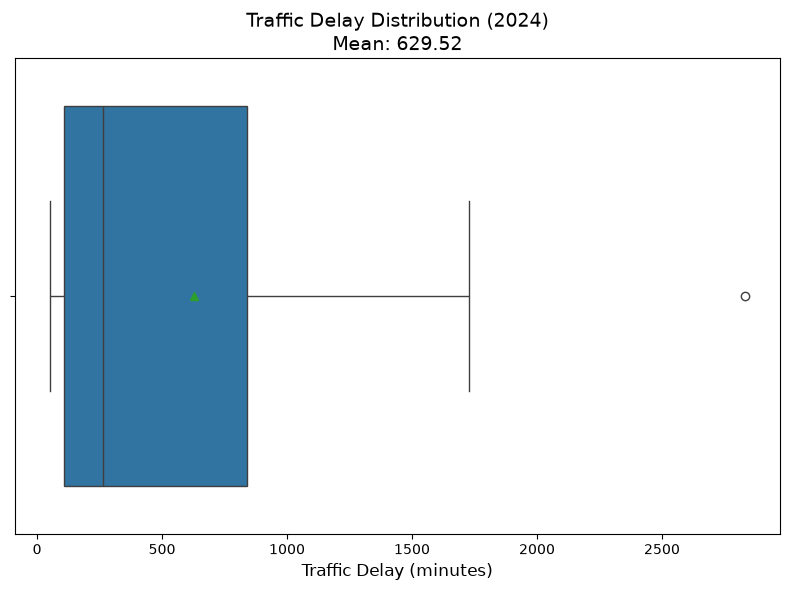

In [20]:
# Create traffic delay boxplot

plt.figure(figsize=(8,6))

sns.boxplot(
    x=merged['jams_delay'],
    showmeans=True
)

# Calculate average traffic delay
mean_value = merged['jams_delay'].mean()

plt.title(f'Traffic Delay Distribution (2024)\nMean: {mean_value:.2f}', fontsize=14)
plt.xlabel('Traffic Delay (minutes)', fontsize=12)

plt.tight_layout()

plt.savefig(
    '../IMAGES/traffic_delay_distribution.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()


In [21]:
# Save figure

plt.savefig(
    '../images/traffic_delay_boxplot.png',
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

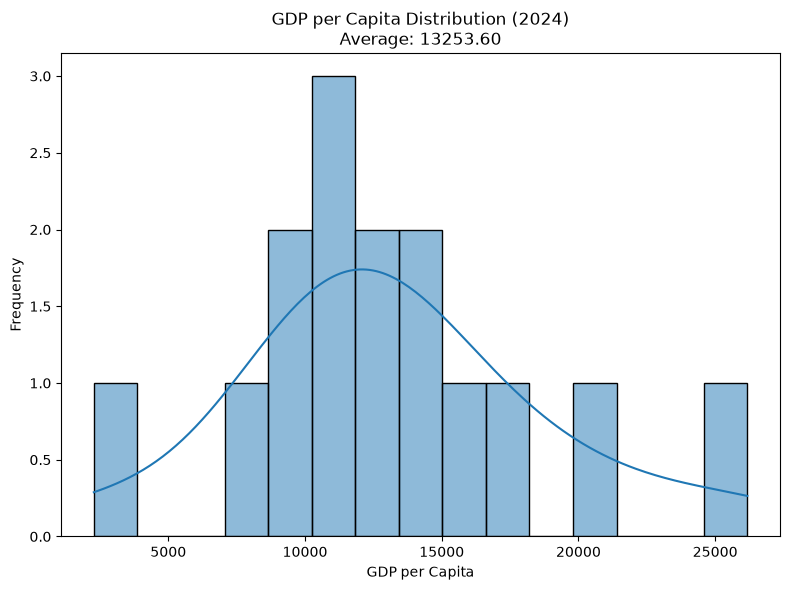

In [30]:
# Create GDP per capita histogram
plt.figure(figsize=(8,6))

sns.histplot(
    data=merged,
    x='city_gdp_capita',
    bins=15,
    kde=True
)

mean_value = merged['city_gdp_capita'].mean()

plt.title(f'GDP per Capita Distribution (2024)\nAverage: {mean_value:.2f}')
plt.xlabel('GDP per Capita')
plt.ylabel('Frequency')
plt.tight_layout()

plt.savefig(
    '../IMAGES/gdp_distribution_histogram.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()


In [23]:
# Save figure

plt.savefig(
    '../images/gdp_distribution_histogram.png',
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

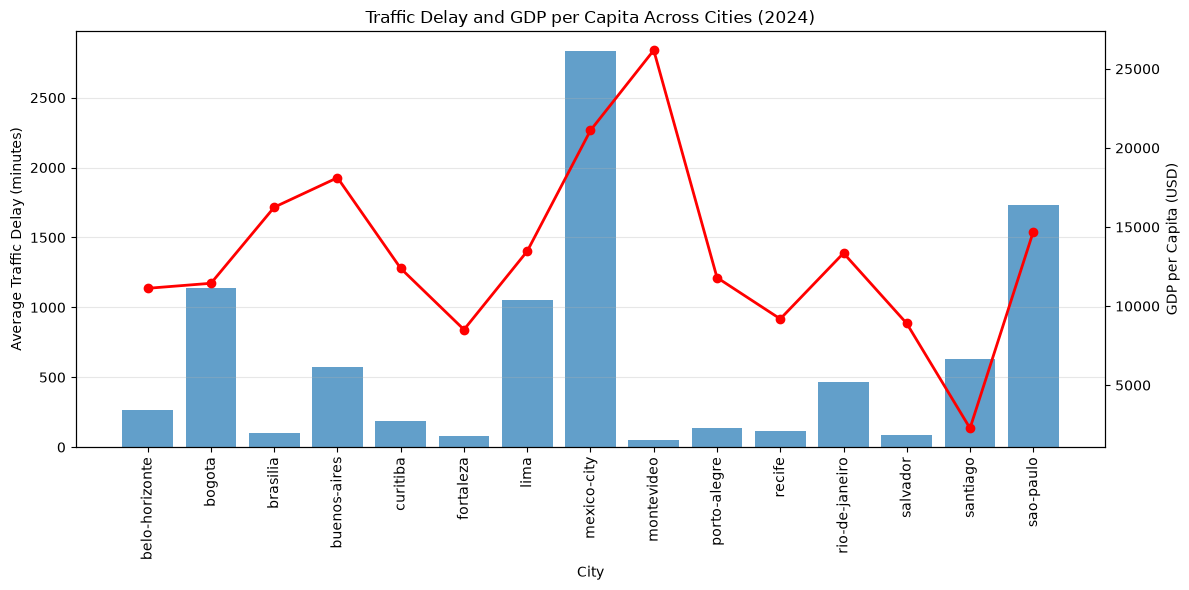

In [31]:
# Create a dual-axis chart to compare traffic delay and GDP per capita

fig, ax1 = plt.subplots(figsize=(12,6))

# Plot average traffic delay as bars
ax1.bar(
    merged['city'],
    merged['jams_delay'],
    alpha=0.7
)

ax1.set_xlabel('City')
ax1.set_ylabel('Average Traffic Delay (minutes)')

# Create a secondary y-axis for GDP per capita
ax2 = ax1.twinx()

ax2.plot(
    merged['city'],
    merged['city_gdp_capita'],
    color='red',
    marker='o',
    linewidth=2
)

ax2.set_ylabel('GDP per Capita (USD)')

# Improve chart appearance
plt.title('Traffic Delay and GDP per Capita Across Cities (2024)')
ax1.tick_params(axis='x', rotation=90)
ax1.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(
    '../IMAGES/traffic_vs_gdp_dual_axis.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [25]:
# Save figure

plt.savefig(
    '../images/traffic_vs_gdp_dual_axis.png',
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

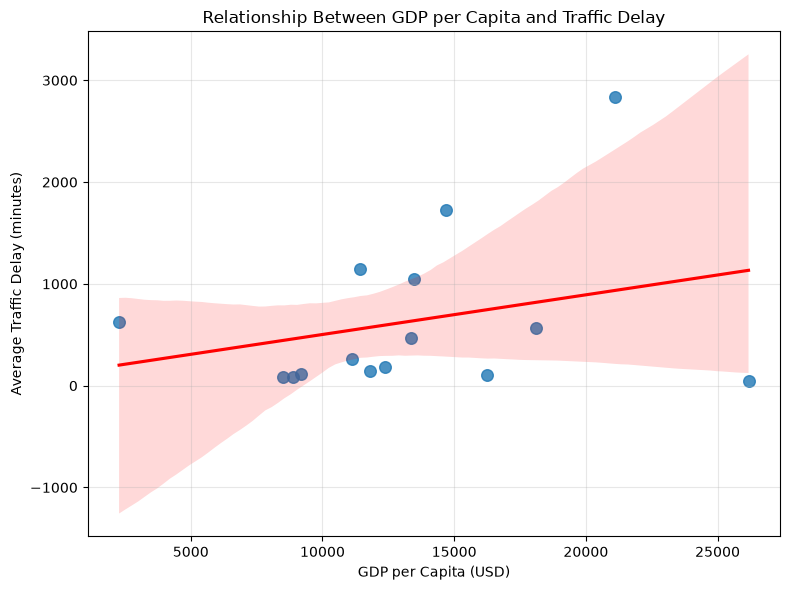

In [32]:
# Create a scatter plot to explore the relationship between GDP per capita and traffic delay

plt.figure(figsize=(8,6))

sns.regplot(
    data=merged,
    x='city_gdp_capita',
    y='jams_delay',
    scatter_kws={'s':70},
    line_kws={'color':'red'}
)

plt.title('Relationship Between GDP per Capita and Traffic Delay')
plt.xlabel('GDP per Capita (USD)')
plt.ylabel('Average Traffic Delay (minutes)')

plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    '../IMAGES/gdp_vs_traffic_scatter.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

In [27]:
# Save figure

plt.savefig(
    '../images/gdp_vs_traffic_scatter.png',
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>

In [28]:
# Calculate the Pearson correlation coefficient

correlation = merged['city_gdp_capita'].corr(merged['jams_delay'])

print(f'Pearson correlation coefficient: {correlation:.3f}')

# Interpret the result
if correlation > 0.7:
    print('Strong positive relationship')
elif correlation > 0.3:
    print('Moderate positive relationship')
elif correlation > -0.3:
    print('Weak or no linear relationship')
elif correlation > -0.7:
    print('Moderate negative relationship')
else:
    print('Strong negative relationship')

Pearson correlation coefficient: 0.283
Weak or no linear relationship


### Correlation Analysis

The Pearson correlation coefficient between GDP per Capita and Average Traffic Delay is **0.283**, indicating a **weak positive linear relationship**.

This result suggests that cities with higher economic output do not necessarily experience higher traffic congestion. Likewise, lower GDP per capita is not consistently associated with lower traffic delay.

The scatter plot supports this finding by showing a wide dispersion of observations and the presence of several outliers. These results indicate that additional variables—such as population density, public transportation quality, urban planning, and road infrastructure—may have a stronger influence on traffic congestion than GDP per capita alone.


## 7. Executive Summary
### 7.1 Business Insights and Recommendations

In [29]:
# Export the final dataset as CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

# 7. Executive Summary

## Project Overview

The objective of this analysis was to investigate the relationship between urban mobility and economic performance across selected cities during 2024. Traffic congestion metrics from the TomTom Traffic Index were integrated with economic indicators from the OECD to explore whether traffic conditions are associated with city-level economic productivity.

## Data Preparation

The analysis included data cleaning, column standardization, date conversion, and numeric formatting. Traffic records were aggregated at the city-year level by calculating annual averages for key mobility indicators. The economic dataset was then merged using an inner join based on city and year, ensuring that only observations available in both datasets were analyzed.

## Exploratory Analysis

Several visualizations were created to understand the data from different perspectives. Boxplots and histograms were used to examine distributions and identify potential outliers. A dual-axis chart compared average traffic delay with GDP per capita across cities, while a scatter plot with a regression line explored the relationship between both variables.

## Key Findings

Mexico City recorded the highest average traffic delay among the analyzed cities, followed by São Paulo and Bogotá. However, the Pearson correlation coefficient between GDP per capita and average traffic delay was **0.283**, indicating a weak positive linear relationship. The scatter plot confirmed that economic performance alone does not explain differences in traffic congestion, suggesting that additional factors such as population density, public transportation systems, urban planning, and infrastructure likely play a significant role.

## Recommendations

Future analyses should incorporate additional explanatory variables, including population size, vehicle ownership, public transportation coverage, and urban density. Applying multivariate regression models or clustering techniques could provide a deeper understanding of the factors influencing urban congestion and help identify cities that would benefit most from transportation infrastructure investments.


## Conclusion

This project demonstrates a complete exploratory data analysis workflow, including data cleaning, aggregation, integration, visualization, and statistical interpretation.

The results show that traffic congestion cannot be explained by economic performance alone, highlighting the importance of considering multiple urban factors when evaluating mobility challenges.

The notebook can serve as a foundation for future predictive modeling or more advanced statistical analyses using additional socioeconomic and transportation variables.